# Malaria Detection - Initial Exploratory Data Analysis

The objective of this project is to develop an efficient computer vision model to detect malaria and classify red blood cell images as parasitized or uninfected.

This code does initial EDA including the following:

* Collecting and evaluating metadata for all the images in the data set.
* Visualization of original images.
* Visualization of color and grayscale image histograms.
* Visualization of images before and after contrast enhancement processing is applied.

# Initializations & Definitions


#### Import libraries and set parameters for run time control

In [1]:
# Reading the training dataset
from google.colab import drive
drive.mount('/content/drive')
myDataPath = "/content/drive/My Drive/Malaria/cell_images/"

#myDataPath = "./cell_images/"
myTrainPath1 = myDataPath + 'train/parasitized/'
myTrainPath0 = myDataPath + 'train/uninfected/'
myTestPath1 = myDataPath + 'test/parasitized/'
myTestPath0 = myDataPath + 'test/uninfected/'

# Parameters to control the execution of the EDA code.
exploreMetadata = True  # turn on/off the execution of some code (takes a long time)

# Import all needed libraries here
#!pip install keras-metrics #used for F1 score
!pip install -U seaborn-image
#!conda install -c conda-forge seaborn-image
import warnings
warnings.filterwarnings("ignore")

import cv2 as cv
from cv2 import equalizeHist
import keras.metrics as km
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt #plotting
import matplotlib.patches as patches
import seaborn as sns
import seaborn_image as isns
from tqdm import tqdm #progress bar
from glob import glob #finds files matching regex
import os,imageio,time #for IO, resizing and runtime profiling
from skimage import img_as_ubyte
from skimage.transform import resize
import imageio.v3 as iio
import random as rn

import keras #keras related
from keras.applications.imagenet_utils import preprocess_input
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from keras.layers import Conv2D, MaxPool2D
from keras.applications.resnet50 import ResNet50

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 7.5 MB/s eta 0:00:00


In [2]:
# We will need lists of files for training and testing
file_list_train1 = os.listdir(myTrainPath1)
file_list_train0 = os.listdir(myTrainPath0)
num_train1 = len(file_list_train1)
num_train0 = len(file_list_train0)
print(f"Number of Training Images of Infected Cells {num_train1}")
print(f"Number of Training Images of Normal Cells {num_train0}")

file_list_test1 = os.listdir(myTestPath1)
file_list_test0 = os.listdir(myTestPath0)
num_test1 = len(file_list_test1)
num_test0 = len(file_list_test0)
print(f"Number of Test Images of Infected Cells {num_test1}")
print(f"Number of Test Images of Normal Cells {num_test0}")

Number of Training Images of Infected Cells 12479
Number of Training Images of Normal Cells 12479
Number of Test Images of Infected Cells 1300
Number of Test Images of Normal Cells 1300


In [23]:
# For now this will import a raw image given complete path
def get_image(file):
  img = imageio.imread(file)
  return img

#### Color image histograms ####

In [4]:
def color_histogram(img, ax):

  #img = get_image(file)
  colors = ("red", "green", "blue")

  # create the histogram plot, with three lines, one for each color
  ax.set_xlim([100, 256]) # don't display the large number of black edge pixels
  ax.set_ylim([0, 2500])
  for channel_id, color in enumerate(colors):
      histogram, bin_edges = np.histogram(
          img[:, :, channel_id], bins=256, range=(0, 256)
      )
      ax.plot(bin_edges[0:-1], histogram, color=color)

  ax.grid(True)
  ax.set_xlabel("Color value",fontsize=10)
  ax.set_ylabel("Pixel count",fontsize=10)

#### Grayscale image histograms

In [5]:
def gray_histogram(img,ax):
  histogram, bin_edges = np.histogram(img, bins=256, range=(0,255))
  ax.set_xlim([10,255]) # ignore black edges of ROIs
  ax.set_ylim([0,2000])
  ax.plot(bin_edges[0:-1], histogram, color=[.1,.1,.1])
  ax.grid(True)
  ax.set_xlabel("Value",fontsize=10)
  ax.set_ylabel("Pixel count",fontsize=10)

#### Looking at the metada may reveal different image file types and file sizes.

In [6]:
def collect_metadata(file_list_path, file_list):
  df = pd.DataFrame(columns=["Mode","xDim","yDim"])
  mode = []
  nx = []
  ny = []
  non_png_files = []
  for file_now in tqdm(file_list):
    f = file_list_path + file_now
    s = os.path.splitext(f)
    if s[1].lower()=='.png':
      md = iio.immeta(f)
      mode.append(md['mode'])
      nx.append(md['shape'][0])
      ny.append(md['shape'][1])
    else:
      non_png_files.append(file_now)
      print(f"Not png format: {file_now}")

  df.Mode = np.transpose(mode)
  df.xDim = np.transpose(nx)
  df.yDim = np.transpose(ny)
  return df

# Look at meta data for the image files

#### Note the following code to collect metadata on the files takes a long time to run. Turn the parameter `exploreMetadata = False` to avoid running these sections everytime the EDA code is run. See the NOTES after this section for observations and insights from the metadata exploration.

In [7]:
if exploreMetadata:
  md_train0 = collect_metadata(myTrainPath0,file_list_train0)
  md_train1 = collect_metadata(myTrainPath1,file_list_train1)
  md_test0 = collect_metadata(myTestPath0,file_list_test0)
  md_test1 = collect_metadata(myTestPath1,file_list_test1)
  md_all = md_train0
  md_all = md_all.append(md_train1, ignore_index = True)
  md_all = md_all.append(md_test0, ignore_index = True)
  md_all = md_all.append(md_test1, ignore_index = True)


100%|██████████| 1300/1300 [07:56<00:00,  2.73it/s]


In [8]:
if exploreMetadata:
  md_all.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27558 entries, 0 to 27557
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Mode    27558 non-null  object
 1   xDim    27558 non-null  int64 
 2   yDim    27558 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 646.0+ KB


In [9]:
if exploreMetadata:
  print(md_all.describe().T) # I don't know why the print statement is needed to see the output?

        count        mean        std   min    25%    50%    75%    max
xDim  27558.0  132.487154  20.015949  46.0  121.0  130.0  142.0  394.0
yDim  27558.0  132.983453  20.619650  40.0  121.0  130.0  145.0  385.0


In [10]:
if exploreMetadata:
  print(md_all.describe(exclude=np.number).T)

      count unique  top   freq
Mode  27558      1  RGB  27558


In [11]:
print(f"num_train0 = {num_train0}")
print(f"num_train1 = {num_train1}")
print(f"num_test0 = {num_test0}")
print(f"num_test1 = {num_test1}")

num_train0 = 12479
num_train1 = 12479
num_test0 = 1300
num_test1 = 1300


### NOTES:

* There are 12,479 training images from each class and 1300 test images from each class. (*note: the training folders originally each had Thumbs.db files which were deleted so the folders only contain images.*)
* All image file extentions are `.png` file types and have RGB color space.
* The image sizes vary. The x dimensions range from 46 to 394 pixels. The y dimensions range from 40 to 385 pixels.



# Visualize Some of the Images

In [12]:
file1 = myTrainPath1+file_list_train1[1000]
file0 = myTrainPath0+file_list_train0[1000]
img1 = get_image(file1)
img0 = get_image(file0)

In [13]:
img0.dtype

dtype('uint8')

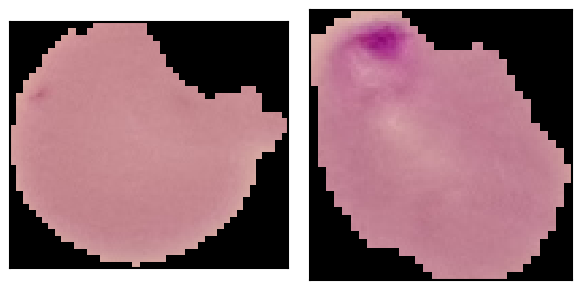

In [14]:
isns.ImageGrid([img0, img1])

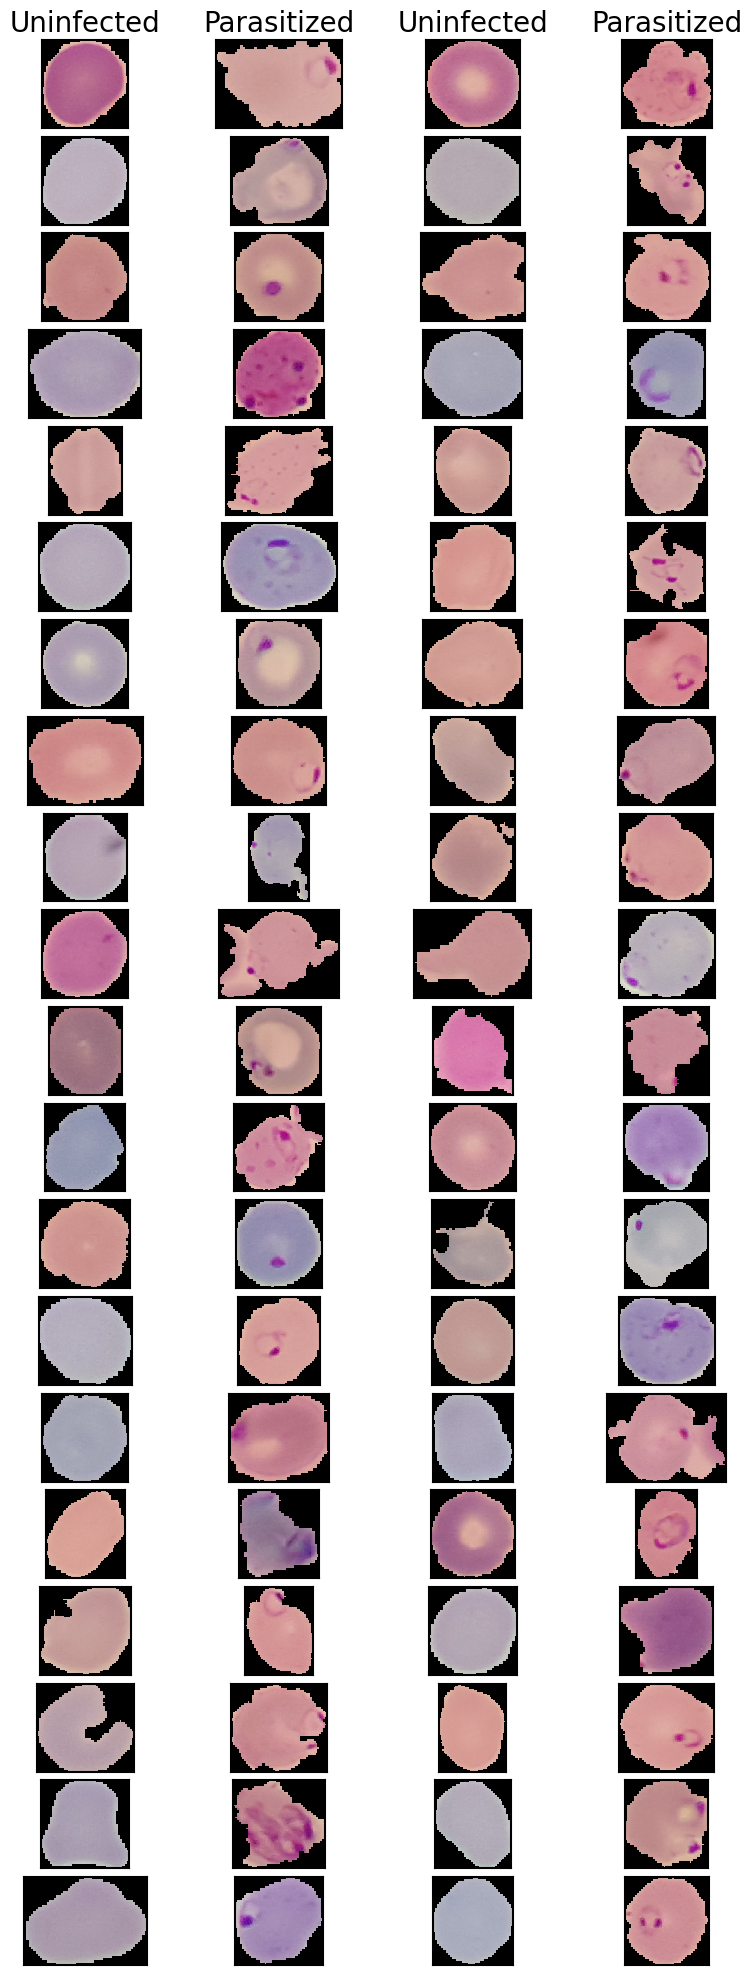

In [15]:
# Initializing variables for subplots
num_rows = 20
num_cols = 4

# Creating subplots
fig, ax = plt.subplots(num_rows, num_cols, figsize = (10, 25))

# Look at a random selection from each class
indx = [i for i in range(0,num_train0)]
rn.seed(42)
indx = rn.sample(indx,num_rows*num_cols)

i = 0
for row in range(num_rows):

  # Get images from infected and normal cells
  img0 = get_image(myTrainPath0 + file_list_train0[indx[i]])
  i += 1
  img1 = get_image(myTrainPath1 + file_list_train1[indx[i]])
  i += 1

  # show images
  isns.imgplot(img0, ax = ax[row,0], describe=False)
  isns.imgplot(img1, ax = ax[row,1], describe=False)

  # Get images from infected and normal cells
  img0 = get_image(myTrainPath0 + file_list_train0[indx[i]])
  i += 1
  img1 = get_image(myTrainPath1 + file_list_train1[indx[i]])
  i += 1

  # show images
  isns.imgplot(img0, ax = ax[row,2], describe=False)
  isns.imgplot(img1, ax = ax[row,3], describe=False)

  # Display the plots and its title
  #isns.ImageGrid([img0, img1])
  if row == 0:
    ax[row,0].set_title("Uninfected", fontsize=20)
    ax[row,1].set_title("Parasitized", fontsize=20)
    ax[row,2].set_title("Uninfected", fontsize=20)
    ax[row,3].set_title("Parasitized", fontsize=20)

plt.subplots_adjust(wspace=0, hspace=0.1)
plt.show()

## NOTES:

* We have 12,479 images from each class for training and 1300 images from each class for testing.
* Images are saved in png (Portable Network Graphic) format and are uint8 data type and have RGB (Red, Green, Blue) color space. The images, with 8 bits/color channel, can represent over 16 million colors (256**3).
* Image files have different sizes. This means if a deep learning method like CNN is used, the images will need to be resized.
* Images appear to have different range of values. This suggests scaling will be needed in preprocessing images.
* The images all have black areas around the edges. They appear to be regions of interest (ROIs) extracted from other original images.
* Many diseased images appear to have spots - presumably the parasites. These may be distinct modes in the image histograms. This suggests a feature extraction method with ML classifier, perhaps a neural network, might work. This approach might be faster than a large deep learning network such as CNN.
* In these diseased images the spots occur in different locations in the image; not all in the center, for example. This suggests spatially invariant methods will be needed.
* Not all of the parasitized images have readily visible spots. In these cases, they appear to have a very uniform color across the cell and may be confused with unifected cells leading false negatives in the classifier. For this reason, we will examine false negatives carefully to try to identify other characteristics that may help recall performance.

# Visualize histograms

##### Color

Text(0.5, 1.0, 'Parasitized')

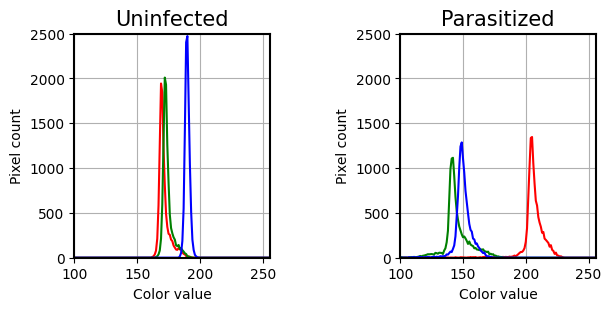

In [16]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout='constrained')
color_histogram(img0, ax[0])
ax[0].set_title("Uninfected")
color_histogram(img1, ax[1])
ax[1].set_title("Parasitized")

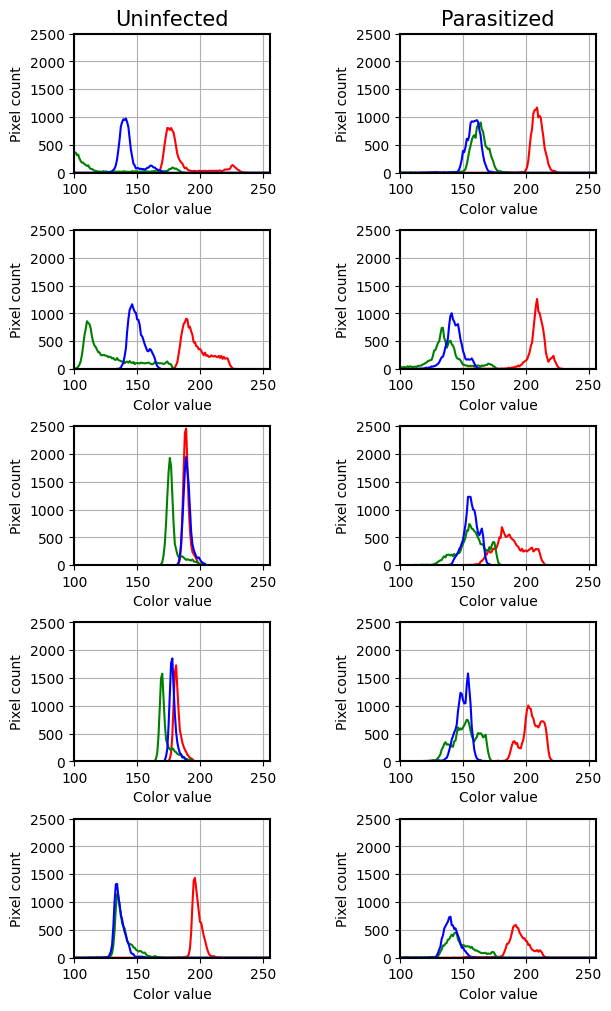

In [17]:
# Initializing variables for subplots
num_rows = 5
num_cols = 2

# Creating subplots
fig, ax = plt.subplots(num_rows, num_cols, figsize = (6, 10), layout='constrained')

# Look at a random selection from each class
indx = [i for i in range(0,num_train0)]
rn.seed(42)
indx = rn.sample(indx,num_rows*num_cols)

i = 0
for row in range(num_rows):

  # Get images from infected and normal cells
  img0 = get_image(myTrainPath0 + file_list_train0[indx[i]])
  i += 1
  img1 = get_image(myTrainPath1 + file_list_train1[indx[i]])
  i += 1

  # show histgrams
  color_histogram(img0, ax = ax[row,0])
  color_histogram(img1, ax = ax[row,1])

  # Display the plots and its title
  if row == 0:
    ax[row,0].set_title("Uninfected", fontsize=15)
    ax[row,1].set_title("Parasitized", fontsize=15)
plt.show()

##### Grayscale

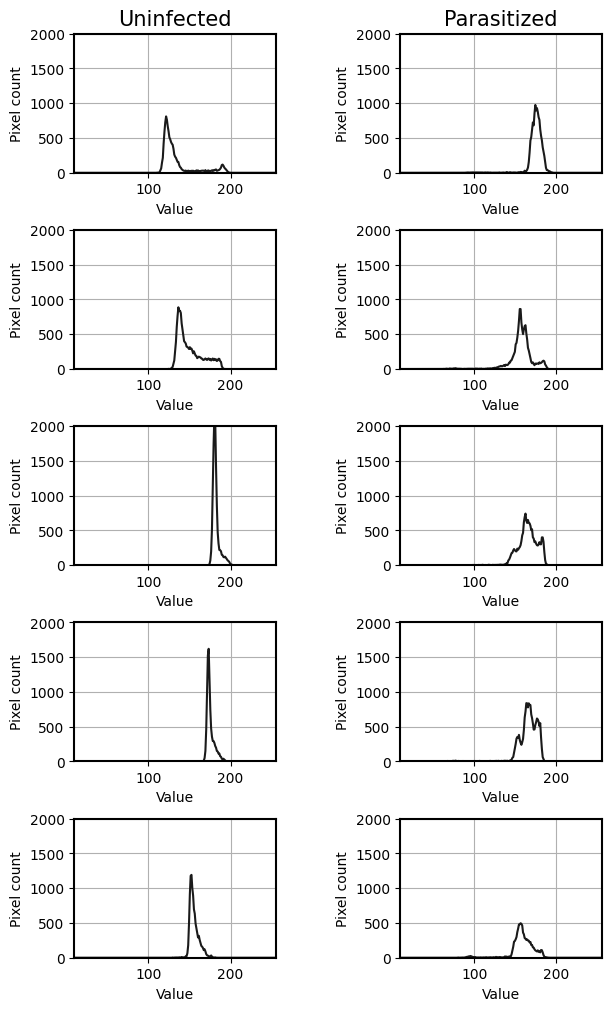

In [18]:
# Initializing variables for subplots
num_rows = 5
num_cols = 2

# Creating subplots
fig, ax = plt.subplots(num_rows, num_cols, figsize = (6, 10), layout='constrained')

# Look at a random selection from each class
indx = [i for i in range(0,num_train0)]
rn.seed(42)
indx = rn.sample(indx,num_rows*num_cols)

i = 0
for row in range(num_rows):

  # Get images from infected and normal cells
  img0 = get_image(myTrainPath0 + file_list_train0[indx[i]])
  img0 = cv.cvtColor(img0, cv.COLOR_RGB2GRAY)
  i += 1
  img1 = get_image(myTrainPath1 + file_list_train1[indx[i]])
  img1 = cv.cvtColor(img1, cv.COLOR_RGB2GRAY)
  i += 1

  # show histgrams
  gray_histogram(img0, ax = ax[row,0])
  gray_histogram(img1, ax = ax[row,1])

  # Display the plots and its title
  if row == 0:
    ax[row,0].set_title("Uninfected", fontsize=15)
    ax[row,1].set_title("Parasitized", fontsize=15)
plt.show()

## NOTES:

* The raw images do not appear to have color or grayscale histograms with patterns that might indicate spots in the parasitized images representing differently from the unifected images. This may be because the spots are relatively small in area and have many fewer pixels compared to the full image.  
* The color and grayscale histograms show what is also apparent in the image visualizations, that the images have a large number of zero values. These appear as black areas around the edges of the images. The provided images appear to be regions of interest (ROIs) extracted from other original images.

# Explore color spaces other than RGB

In [19]:
img0 = get_image(myTrainPath0 + file_list_train0[1000])
img1 = get_image(myTrainPath1 + file_list_train1[1000])
np.shape(img0)

(115, 130, 3)

In [20]:
import cv2
from google.colab.patches import cv2_imshow
maps = np.transpose([x for x in dir(cv) if x.startswith('COLOR_RGB2')] )
print(maps)

['COLOR_RGB2BGR' 'COLOR_RGB2BGR555' 'COLOR_RGB2BGR565' 'COLOR_RGB2BGRA'
 'COLOR_RGB2GRAY' 'COLOR_RGB2HLS' 'COLOR_RGB2HLS_FULL' 'COLOR_RGB2HSV'
 'COLOR_RGB2HSV_FULL' 'COLOR_RGB2LAB' 'COLOR_RGB2LUV' 'COLOR_RGB2Lab'
 'COLOR_RGB2Luv' 'COLOR_RGB2RGBA' 'COLOR_RGB2XYZ' 'COLOR_RGB2YCR_CB'
 'COLOR_RGB2YCrCb' 'COLOR_RGB2YUV' 'COLOR_RGB2YUV_I420'
 'COLOR_RGB2YUV_IYUV' 'COLOR_RGB2YUV_YV12']


Text(0.5, 1.0, 'YUV')

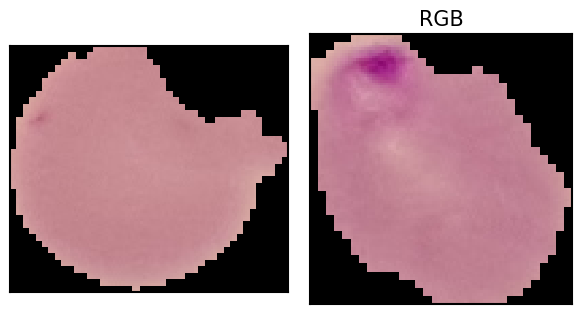

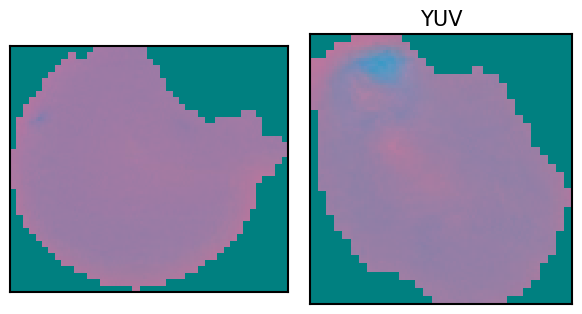

In [21]:
img0_new = cv2.cvtColor(img0, cv2.COLOR_RGB2YUV)
img1_new = cv2.cvtColor(img1, cv2.COLOR_RGB2YUV)
#cv2_imshow(img0_new)
#cv2_imshow(img1_new)
isns.ImageGrid([img0, img1])
plt.title('RGB')
isns.ImageGrid([img0_new, img1_new])
plt.title('YUV')

# Explore image preprocessing for visual improvements

#### Let's see if we can improve the visual differences between uninfected and parasitized cell images

#### Histogram equalization

In [22]:
%matplotlib inline
# Initializing variables for subplots
num_rows = 20
num_cols = 4

# Creating subplots
fig, ax = plt.subplots(num_rows, num_cols, figsize = (15, 25))

# Look at a random selection from each class
indx = [i for i in range(0,num_train0)]
rn.seed(42)
indx = rn.sample(indx,num_rows*num_cols)

i = 0
for row in range(num_rows):

  # Get images from infected and normal cells
  img0_raw = get_image(myTrainPath0 + file_list_train0[indx[i]])
  img0_raw = cv2.cvtColor(img0_raw, cv2.COLOR_RGB2GRAY)
  img0_eq = equalizeHist(img0_raw)
  img0 = np.hstack((img0_raw,img0_eq))
  i += 1
  img1_raw = get_image(myTrainPath1 + file_list_train1[indx[i]])
  img1_raw = cv2.cvtColor(img1_raw, cv2.COLOR_RGB2GRAY)
  img1_eq = equalizeHist(img1_raw)
  img1 = np.hstack((img1_raw,img1_eq))
  i += 1

  # show images
  isns.imgplot(img0, ax = ax[row,0], describe=False)
  isns.imgplot(img1, ax = ax[row,1], describe=False)

  # Get images from infected and normal cells
  img0_raw = get_image(myTrainPath0 + file_list_train0[indx[i]])
  img0_raw = cv2.cvtColor(img0_raw, cv2.COLOR_RGB2GRAY)
  img0_eq = equalizeHist(img0_raw)
  img0 = np.hstack((img0_raw,img0_eq))
  i += 1
  img1_raw = get_image(myTrainPath1 + file_list_train1[indx[i]])
  img1_raw = cv2.cvtColor(img1_raw, cv2.COLOR_RGB2GRAY)
  img1_eq = equalizeHist(img1_raw)
  img1 = np.hstack((img1_raw,img1_eq))
  i += 1

  # show images
  isns.imgplot(img0, ax = ax[row,2], describe=False)
  isns.imgplot(img1, ax = ax[row,3], describe=False)

  # Display the plots and its title
  #isns.ImageGrid([img0, img1])
  if row == 0:
    ax[row,0].set_title("Uninfected", fontsize=20)
    ax[row,1].set_title("Parasitized", fontsize=20)
    ax[row,2].set_title("Uninfected", fontsize=20)
    ax[row,3].set_title("Parasitized", fontsize=20)

plt.subplots_adjust(wspace=0, hspace=0.1)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## NOTES

* These images show the uninfected and parasitized images before and after histogram equalization side by side.
* The method enhances the contrast in the images. In this case, the parasites are more distinct in the parasitized images which may improve recall. However, background is enhanced in the uninfected images which may cause false positives and reduce precision performance.